In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

warnings.filterwarnings("ignore")         
pd.set_option("display.max_columns", 30) 
pd.set_option("display.width", 120)

print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("sklearn:", sklearn.__version__) 

NumPy  : 2.5.2
Pandas : 3.0.6
sklearn: 1.9.1


In [3]:
s = pd.Series([120, 95, 140], index=["Mon", "Tue", "Wed"], name="rooms_sold")
print(s, "\n")
print("s[' Tue'] =", s["Tue"],"| s.mean() =", s.mean())

Mon    120
Tue     95
Wed    140
Name: rooms_sold, dtype: int64 

s[' Tue'] = 95 | s.mean() = 118.33333333333333


In [4]:
orders = pd.DataFrame({
    "order_id":    range(1001, 1013),
    "customer_id": [1, 2, 3, 1, 4, 2, 5, 3, 6, 1, 7, 4],
    "city":        ["Delhi", "Mumbai", "Ludhiana", "Delhi", "Pune", "Mumbai",
                    "Delhi", "Ludhiana", "Chandigarh", "Delhi", "Pune", "Pune"],
    "product":     ["Laptop", "Phone", "Tablet", "Phone", "Laptop", "Headphones",
                    "Phone", "Laptop", "Tablet", "Headphones", "Phone", "Laptop"],
    "qty":         [1, 2, 1, 1, 1, 3, 2, 1, 2, 2, 1, 1],
    "unit_price":  [55000, 20000, 25000, 20000, 55000, 3000, 20000, 55000, 25000, 3000, 20000, 55000],
    "order_date":  pd.to_datetime(["2025-01-05", "2025-01-12", "2025-02-03", "2025-02-14",
                                   "2025-02-20", "2025-03-01", "2025-03-09", "2025-03-15",
                                   "2025-04-02", "2025-04-18", "2025-05-05", "2025-05-21"]),
    "status":      ["Delivered", "Delivered", "Cancelled", "Delivered", "Delivered", "Delivered",
                    "Returned", "Delivered", "Delivered", "Cancelled", "Delivered", "Delivered"],
})
orders

,order_id,customer_id,city,product,qty,unit_price,order_date,status
0,1001,1,Delhi,Laptop,1,55000,2025-01-05,Delivered
1,1002,2,Mumbai,Phone,2,20000,2025-01-12,Delivered
2,1003,3,Ludhiana,Tablet,1,25000,2025-02-03,Cancelled
3,1004,1,Delhi,Phone,1,20000,2025-02-14,Delivered
4,1005,4,Pune,Laptop,1,55000,2025-02-20,Delivered
5,1006,2,Mumbai,Headphones,3,3000,2025-03-01,Delivered
6,1007,5,Delhi,Phone,2,20000,2025-03-09,Returned
7,1008,3,Ludhiana,Laptop,1,55000,2025-03-15,Delivered
8,1009,6,Chandigarh,Tablet,2,25000,2025-04-02,Delivered
9,1010,1,Delhi,Headphones,2,3000,2025-04-18,Cancelled


In [5]:
print("Shape:", orders.shape)
print()
orders.info()

Shape: (12, 8)

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     12 non-null     int64         
 1   customer_id  12 non-null     int64         
 2   city         12 non-null     str           
 3   product      12 non-null     str           
 4   qty          12 non-null     int64         
 5   unit_price   12 non-null     int64         
 6   order_date   12 non-null     datetime64[us]
 7   status       12 non-null     str           
dtypes: datetime64[us](1), int64(4), str(3)
memory usage: 900.0 bytes


In [6]:
print(orders.describe())
print()
print(orders["status"].value_counts())
print()
print("Unique cities:", orders["city"].nunique(), "->", orders["city"].unique())

          order_id  customer_id      qty    unit_price           order_date
count    12.000000    12.000000  12.0000     12.000000                   12
mean   1006.500000     3.250000   1.5000  29666.666667  2025-03-08 22:00:00
min    1001.000000     1.000000   1.0000   3000.000000  2025-01-05 00:00:00
25%    1003.750000     1.750000   1.0000  20000.000000  2025-02-11 06:00:00
50%    1006.500000     3.000000   1.0000  22500.000000  2025-03-05 00:00:00
75%    1009.250000     4.250000   2.0000  55000.000000  2025-04-06 00:00:00
max    1012.000000     7.000000   3.0000  55000.000000  2025-05-21 00:00:00
std       3.605551     2.005674   0.6742  20015.145780                  NaN

status
Delivered    9
Cancelled    2
Returned     1
Name: count, dtype: int64

Unique cities: 5 -> <StringArray>
['Delhi', 'Mumbai', 'Ludhiana', 'Pune', 'Chandigarh']
Length: 5, dtype: str


In [7]:
print(orders["city"].head(3).tolist())
print()
print(orders[["order_id", "city", "qty"]].head(3))
print()
print("loc  (label-based)   :", orders.loc[0:2, "product"].tolist(), " <- loc INCLUDES the end label")
print("iloc (position-based):", orders.iloc[0:2, 3].tolist(), " <- iloc EXCLUDES the end position")

['Delhi', 'Mumbai', 'Ludhiana']

   order_id      city  qty
0      1001     Delhi    1
1      1002    Mumbai    2
2      1003  Ludhiana    1

loc  (label-based)   : ['Laptop', 'Phone', 'Tablet']  <- loc INCLUDES the end label
iloc (position-based): ['Laptop', 'Phone']  <- iloc EXCLUDES the end position


In [8]:
# Single condition
delivered = orders[orders["status"] == "Delivered"]
print("Delivered orders:", len(delivered))

# Multiple conditions: use & | ~ and put EACH condition in parentheses
big_delhi = orders[(orders["city"] == "Delhi") & (orders["unit_price"] > 10000)]
print("Delhi orders above 10,000:", len(big_delhi))

# isin, between, string contains
print("\nPune or Mumbai:", orders[orders["city"].isin(["Pune", "Mumbai"])]["order_id"].tolist())
print("Price between 20k and 30k:", orders[orders["unit_price"].between(20000, 30000)]["order_id"].tolist())
print("Product contains 'phone':", orders[orders["product"].str.contains("phone", case=False)]["product"].unique())

# query(): readable alternative
print("\nUsing query():")
orders.query("qty >= 2 and status == 'Delivered'")[["order_id", "product", "qty", "status"]]

Delivered orders: 9
Delhi orders above 10,000: 3

Pune or Mumbai: [1002, 1005, 1006, 1011, 1012]
Price between 20k and 30k: [1002, 1003, 1004, 1007, 1009, 1011]
Product contains 'phone': <StringArray>
['Phone', 'Headphones']
Length: 2, dtype: str

Using query():


,order_id,product,qty,status
1,1002,Phone,2,Delivered
5,1006,Headphones,3,Delivered
8,1009,Tablet,2,Delivered


In [9]:
df = orders.copy()                                 # work on a copy so `orders` stays original

df["revenue"] = df["qty"] * df["unit_price"]       # new column from math
df["is_bulk"] = df["qty"] >= 2                     # True/False column
df["price_band"] = np.where(df["unit_price"] > 30000, "Premium", "Standard")   # if-else
df["city_upper"] = df["city"].str.upper()          # string method
df["month"] = df["order_date"].dt.month            # date part

# map(): replace values using a dictionary
df["status_code"] = df["status"].map({"Delivered": 1, "Returned": 0, "Cancelled": 0})

# apply(): run any Python function per value (slower than vectorised, use when needed)
df["label"] = df["revenue"].apply(lambda r: "High" if r >= 50000 else "Normal")

df[["order_id", "revenue", "is_bulk", "price_band", "month", "status_code", "label", "qty", "unit_price", "city_upper"]].head()

,order_id,revenue,is_bulk,price_band,month,status_code,label,qty,unit_price,city_upper
0,1001,55000,False,Premium,1,1,High,1,55000,DELHI
1,1002,40000,True,Standard,1,1,Normal,2,20000,MUMBAI
2,1003,25000,False,Standard,2,0,Normal,1,25000,LUDHIANA
3,1004,20000,False,Standard,2,1,Normal,1,20000,DELHI
4,1005,55000,False,Premium,2,1,High,1,55000,PUNE


In [10]:
print(df.sort_values("revenue", ascending=False)[["order_id", "city", "revenue"]].head(10))
print()
print("nlargest shortcut:")
print(df.nlargest(5, "revenue")[["order_id", "product", "revenue"]])

    order_id        city  revenue
0       1001       Delhi    55000
11      1012        Pune    55000
7       1008    Ludhiana    55000
4       1005        Pune    55000
8       1009  Chandigarh    50000
6       1007       Delhi    40000
1       1002      Mumbai    40000
2       1003    Ludhiana    25000
3       1004       Delhi    20000
10      1011        Pune    20000

nlargest shortcut:
    order_id product  revenue
0       1001  Laptop    55000
4       1005  Laptop    55000
7       1008  Laptop    55000
11      1012  Laptop    55000
8       1009  Tablet    50000


In [11]:
valid = df[df["status"] == "Delivered"]       # only count delivered orders as real revenue

# One key, one metric
print(valid.groupby("city")["revenue"].sum().sort_values(ascending=False))

city
Pune          130000
Delhi          75000
Ludhiana       55000
Chandigarh     50000
Mumbai         49000
Name: revenue, dtype: int64


In [12]:
summary = valid.groupby("city").agg(
    orders=("order_id", "count"),
    total_revenue=("revenue", "sum"),
    avg_order_value=("revenue", "mean"),
    unique_customers=("customer_id", "nunique"),
).sort_values("total_revenue", ascending=False)
summary

,orders,total_revenue,avg_order_value,unique_customers
city,,,,
Pune,3,130000,43333.333333,2
Delhi,2,75000,37500.000000,1
Ludhiana,1,55000,55000.000000,1
Chandigarh,1,50000,50000.000000,1
Mumbai,2,49000,24500.000000,1


In [13]:
print(valid.groupby(["city", "product"])["revenue"].sum().head(6))
print()
pivot = valid.pivot_table(index="city", columns="product", values="revenue", aggfunc="sum", fill_value=0)
pivot

city        product   
Chandigarh  Tablet        50000
Delhi       Laptop        55000
            Phone         20000
Ludhiana    Laptop        55000
Mumbai      Headphones     9000
            Phone         40000
Name: revenue, dtype: int64



product,Headphones,Laptop,Phone,Tablet
city,,,,
Chandigarh,0,0,0,50000
Delhi,0,55000,20000,0
Ludhiana,0,55000,0,0
Mumbai,9000,0,40000,0
Pune,0,110000,20000,0


In [14]:
df["city_total_revenue"] = df.groupby("city")["revenue"].transform("sum")
df["share_of_city_revenue"] = (df["revenue"] / df["city_total_revenue"]).round(2)
df[["order_id", "city", "revenue", "city_total_revenue", "share_of_city_revenue"]].head(5)

,order_id,city,revenue,city_total_revenue,share_of_city_revenue
0,1001,Delhi,55000,121000,0.45
1,1002,Mumbai,40000,49000,0.82
2,1003,Ludhiana,25000,80000,0.31
3,1004,Delhi,20000,121000,0.17
4,1005,Pune,55000,130000,0.42


In [15]:
customers = pd.DataFrame({
    "customer_id": [1, 2, 3, 4, 5, 6, 7],          
    "name":        ["Aman", "Priya", "Rahul", "Simran", "Karan", "Neha", "John"],
    "segment":     ["Gold", "Silver", "Gold", "Bronze", "Silver", "Gold", "Gold"],
})

inner = orders.merge(customers, on="customer_id", how="inner")
left  = orders.merge(customers, on="customer_id", how="left")

print("orders rows :", len(orders))
print("inner join  :", len(inner), "rows  <- customer 7's order disappeared silently!")
print("left join   :", len(left), "rows  <- nothing lost, missing info shows as NaN")
print()
print(left[["order_id", "customer_id", "name", "segment"]])

orders rows : 12
inner join  : 12 rows  <- customer 7's order disappeared silently!
left join   : 12 rows  <- nothing lost, missing info shows as NaN

    order_id  customer_id    name segment
0       1001            1    Aman    Gold
1       1002            2   Priya  Silver
2       1003            3   Rahul    Gold
3       1004            1    Aman    Gold
4       1005            4  Simran  Bronze
5       1006            2   Priya  Silver
6       1007            5   Karan  Silver
7       1008            3   Rahul    Gold
8       1009            6    Neha    Gold
9       1010            1    Aman    Gold
10      1011            7    John    Gold
11      1012            4  Simran  Bronze


In [16]:
d = pd.DataFrame({"raw": ["2025-01-05", "2025-02-14", "not available", "2025-03-09"]})
print(d)
d["date"] = pd.to_datetime(d["raw"], errors="coerce")      
d["year"]       = d["date"].dt.year
d["month_name"] = d["date"].dt.month_name()
d["weekday"]    = d["date"].dt.day_name()
d["is_weekend"] = d["date"].dt.dayofweek >= 5               
print(d)

# Monthly revenue trend
monthly = df.groupby(df["order_date"].dt.to_period("M"))["revenue"].sum()
print("\nMonthly revenue:\n", monthly)

             raw
0     2025-01-05
1     2025-02-14
2  not available
3     2025-03-09
             raw       date    year month_name weekday  is_weekend
0     2025-01-05 2025-01-05  2025.0    January  Sunday        True
1     2025-02-14 2025-02-14  2025.0   February  Friday       False
2  not available        NaT     NaN        NaN     NaN       False
3     2025-03-09 2025-03-09  2025.0      March  Sunday        True

Monthly revenue:
 order_date
2025-01     95000
2025-02    100000
2025-03    104000
2025-04     56000
2025-05     75000
Freq: M, Name: revenue, dtype: int64


In [17]:
messy = pd.Series(["Delhi", " delhi ", "DELHI", "New Delhi", "Dehli"])
print("Before:", messy.value_counts().to_dict())

clean_city = (messy.str.strip()          
                    .str.title()         
                    .replace({"New Delhi": "Delhi", "Dehli": "Delhi"}))    
print("After :", clean_city.value_counts().to_dict())

Before: {'Delhi': 1, ' delhi ': 1, 'DELHI': 1, 'New Delhi': 1, 'Dehli': 1}
After : {'Delhi': 5}


In [19]:
m = pd.DataFrame({
    "name":  ["A", "B", "C", "D", "E"],
    "age":   [25, np.nan, 31, np.nan, 40],
    "city":  ["Delhi", "Pune", None, "Delhi", "Pune"],
    "score": [88, 92, 75, np.nan, 81],
}) 

print("Missing per column:\n", m.isna().sum(), "\n")
print("Missing % per column:\n", (m.isna().mean() * 100).round(1), "\n")

print("dropna() keeps only complete rows:", len(m.dropna()), "of", len(m), "rows  <- we lose a lot!")

m["age"]   = m["age"].fillna(m["age"].median())        # numeric: median is robust to outliers
m["city"]  = m["city"].fillna("Unknown")               # categorical: explicit 'Unknown' label
m["score"] = m["score"].fillna(m["score"].mean())

m

Missing per column:
 name     0
age      2
city     1
score    1
dtype: int64 

Missing % per column:
 name      0.0
age      40.0
city     20.0
score    20.0
dtype: float64 

dropna() keeps only complete rows: 2 of 5 rows  <- we lose a lot!


,name,age,city,score
0,A,25.0,Delhi,88.0
1,B,31.0,Pune,92.0
2,C,31.0,Unknown,75.0
3,D,31.0,Delhi,84.0
4,E,40.0,Pune,81.0


In [ ]:
"""
CSV = pd.read_csv("f.csv")
EXCEL = pd.read_excel("f.xlsx")
SQL = pd.read_sql_query(sql, conn)
JSON = pd.read_json("f.json")


CSV = df.to_csv("f.csv")
EXCEL = df.to_excel("f.xlsx")
SQL = df.to_sql(sql, conn)
JSON = df.tp_json("f.json")

"""

In [20]:
import sqlite3

# Pandas <-> SQL: this is how you pull enterprise data into an ML workflow
conn = sqlite3.connect(":memory:")
orders.to_sql("orders", conn, index=False, if_exists="replace")

sql = """
SELECT city, SUM(qty * unit_price) AS revenue
FROM orders
WHERE status = 'Delivered'
GROUP BY city
ORDER BY revenue DESC
"""
print(pd.read_sql_query(sql, conn))
conn.close()

         city  revenue
0        Pune   130000
1       Delhi    75000
2    Ludhiana    55000
3  Chandigarh    50000
4      Mumbai    49000


| SQL | Pandas |
|---|---|
| `SELECT a, b FROM t` | `t[["a", "b"]]` |
| `WHERE x > 5` | `t[t["x"] > 5]` |
| `ORDER BY x DESC` | `t.sort_values("x", ascending=False)` |
| `GROUP BY g` + `SUM(x)` | `t.groupby("g")["x"].sum()` |
| `COUNT(DISTINCT c)` | `t["c"].nunique()` |
| `JOIN ... ON k` | `t1.merge(t2, on="k", how="inner")` |
| `CASE WHEN` | `np.where(...)` or `.map(...)` |
| `LIMIT 10` | `t.head(10)` |

In [21]:
def make_hotel_bookings(n=5000, seed=42):
    """Create a realistic but messy hotel-bookings table (synthetic data)."""
    rng = np.random.default_rng(seed)

    hotel          = rng.choice(["City Hotel", "Resort Hotel"], size=n, p=[0.6, 0.4])
    lead_time      = np.clip(rng.gamma(1.6, 55, n), 0, 500).astype(int)
    check_in       = pd.Timestamp("2024-01-01") + pd.to_timedelta(rng.integers(0, 730, n), unit="D")
    stay_nights    = rng.choice([1, 2, 3, 4, 5, 6, 7, 10, 14], size=n,
                                p=[.18, .25, .20, .13, .10, .05, .05, .03, .01])
    adults         = rng.choice([1, 2, 3, 4], size=n, p=[.20, .65, .10, .05])
    children       = rng.choice([0, 1, 2], size=n, p=[.85, .10, .05]).astype(float)
    meal_plan      = rng.choice(["BB", "HB", "FB", "SC"], size=n, p=[.60, .20, .05, .15])
    countries      = ["IN", "GB", "US", "DE", "FR", "ES", "AE", "AU", "CA", "IT", "BR", "JP", "SG", "NL", "ZA"]
    weights        = np.array([20, 14, 12, 9, 8, 6, 6, 5, 4, 4, 3, 3, 3, 2, 1], dtype=float)
    country        = rng.choice(countries, size=n, p=weights / weights.sum())
    market_segment = rng.choice(["Online TA", "Offline TA/TO", "Direct", "Corporate", "Groups"],
                                size=n, p=[.45, .20, .15, .12, .08])
    deposit_type   = rng.choice(["No Deposit", "Non Refund", "Refundable"], size=n, p=[.86, .10, .04])
    room_type      = rng.choice(list("ABCDEF"), size=n, p=[.35, .25, .15, .12, .08, .05])
    is_repeated    = rng.choice([0, 1], size=n, p=[.95, .05])
    prev_cancel    = rng.choice([0, 1, 2], size=n, p=[.93, .05, .02])
    special_req    = np.clip(rng.poisson(0.8, n), 0, 5)

    # Average Daily Rate (price per night): depends on season and room type
    month   = check_in.month.to_numpy()
    season  = 1 + 0.25 * np.sin((month - 4) / 12 * 2 * np.pi)
    base    = np.where(hotel == "City Hotel", 105, 95)
    uplift  = pd.Series(room_type).map({"A": 1.0, "B": 1.05, "C": 1.1, "D": 1.2, "E": 1.3, "F": 1.5}).to_numpy()
    adr     = np.round(base * season * uplift * rng.lognormal(0, 0.2, n), 2)

    # Hidden "truth": what really drives cancellations
    logit = (-1.4 + 0.006 * lead_time + 0.9 * (market_segment == "Online TA")
             + 0.8 * (deposit_type == "Non Refund") - 1.0 * is_repeated
             - 0.5 * special_req + 0.8 * prev_cancel + 0.004 * (adr - 100))
    is_canceled = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

    df = pd.DataFrame({
        "booking_id": np.arange(10001, 10001 + n), "hotel": hotel,
        "check_in_date": check_in.strftime("%Y-%m-%d").to_numpy(),
        "lead_time": lead_time, "stay_nights": stay_nights, "adults": adults, "children": children,
        "meal_plan": meal_plan, "country": country, "market_segment": market_segment,
        "deposit_type": deposit_type, "room_type": room_type, "is_repeated_guest": is_repeated,
        "previous_cancellations": prev_cancel, "special_requests": special_req,
        "adr": adr, "is_canceled": is_canceled,
    })

    # ---- Now make it MESSY, like a real export ----
    def pick(k):
        return rng.choice(n, size=k, replace=False)

    i = pick(300)                                               # inconsistent text in hotel names
    df.loc[i[:100], "hotel"]    = df.loc[i[:100], "hotel"].str.lower()
    df.loc[i[100:200], "hotel"] = df.loc[i[100:200], "hotel"].str.upper()
    df.loc[i[200:], "hotel"]    = " " + df.loc[i[200:], "hotel"] + " "

    df.loc[pick(150), "country"] = np.nan                       # missing country
    gb = df.index[df["country"] == "GB"]
    df.loc[rng.choice(gb, size=len(gb) // 3, replace=False), "country"] = "UK"   # same country, two codes

    df.loc[pick(100), "meal_plan"] = "Undefined"                # placeholder meaning "unknown"
    df.loc[pick(50), "meal_plan"]  = np.nan
    df.loc[pick(100), "children"]  = np.nan
    df.loc[pick(150), "adr"]       = np.nan                     # missing price
    df.loc[pick(5), "adr"]         = -1.0                       # impossible price
    df.loc[pick(5), "adr"]         = 5400.0                     # typing error (extra zero)
    df.loc[pick(8), "lead_time"]   = rng.integers(-30, -1, 8)   # negative lead time
    df.loc[pick(6), "lead_time"]   = rng.integers(800, 1200, 6) # 2-3 years ahead: unrealistic
    df.loc[pick(10), "stay_nights"] = 0                         # zero-night stay
    no_guest = pick(8)
    df.loc[no_guest, "adults"] = 0
    df.loc[no_guest, "children"] = 0                            # booking with nobody in it
    df.loc[pick(50), "check_in_date"] = "not available"         # text inside a date column

    dup = df.sample(60, random_state=seed)                      # exact duplicate rows (double export)
    df = pd.concat([df, dup]).sample(frac=1, random_state=seed).reset_index(drop=True)
    return df


raw_export = make_hotel_bookings()
print(raw_export.head(5))
raw_export.to_csv("hotel_bookings_raw.csv", index=False)     # pretend this is the file from the PMS
print("Saved hotel_bookings_raw.csv ->", raw_export.shape)

   booking_id         hotel check_in_date  lead_time  stay_nights  adults  children meal_plan country market_segment  \
0       13106  Resort Hotel    2025-02-21         19            2       2       0.0        BB      AE         Groups   
1       13787  Resort Hotel    2025-11-20         76            3       2       0.0        HB      US  Offline TA/TO   
2       14330  Resort Hotel    2024-04-27         11            1       3       0.0        BB      GB         Groups   
3       11256  Resort Hotel    2025-06-08         32            4       2       2.0        BB      CA      Online TA   
4       12252  Resort Hotel    2024-07-22         53            1       2       0.0        HB      US         Direct   

  deposit_type room_type  is_repeated_guest  previous_cancellations  special_requests     adr  is_canceled  
0   No Deposit         C                  0                       0                 1   69.58            0  
1   No Deposit         C                  0                  

In [22]:
raw = pd.read_csv("hotel_bookings_raw.csv")
raw.head(8)

,booking_id,hotel,check_in_date,lead_time,stay_nights,adults,children,meal_plan,country,market_segment,deposit_type,room_type,is_repeated_guest,previous_cancellations,special_requests,adr,is_canceled
0,13106,Resort Hotel,2025-02-21,19,2,2,0.0,BB,AE,Groups,No Deposit,C,0,0,1,69.58,0
1,13787,Resort Hotel,2025-11-20,76,3,2,0.0,HB,US,Offline TA/TO,No Deposit,C,0,0,1,116.25,0
2,14330,Resort Hotel,2024-04-27,11,1,3,0.0,BB,GB,Groups,No Deposit,B,1,0,1,NaN,0
3,11256,Resort Hotel,2025-06-08,32,4,2,2.0,BB,CA,Online TA,No Deposit,D,1,0,0,155.52,0
4,12252,Resort Hotel,2024-07-22,53,1,2,0.0,HB,US,Direct,No Deposit,A,0,0,1,124.02,0
5,13707,City Hotel,2025-01-06,46,2,1,0.0,BB,UK,Online TA,No Deposit,E,0,0,0,100.96,0
6,14939,Resort Hotel,2025-05-19,6,10,4,0.0,SC,IN,Offline TA/TO,No Deposit,A,0,1,0,158.46,0
7,13529,Resort Hotel,2025-06-08,86,3,3,0.0,BB,DE,Online TA,No Deposit,B,0,0,0,140.77,0


In [23]:
print("Rows x columns:", raw.shape)
print()
raw.info()

Rows x columns: (5060, 17)

<class 'pandas.DataFrame'>
RangeIndex: 5060 entries, 0 to 5059
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   booking_id              5060 non-null   int64  
 1   hotel                   5060 non-null   str    
 2   check_in_date           5060 non-null   str    
 3   lead_time               5060 non-null   int64  
 4   stay_nights             5060 non-null   int64  
 5   adults                  5060 non-null   int64  
 6   children                4960 non-null   float64
 7   meal_plan               5008 non-null   str    
 8   country                 4907 non-null   str    
 9   market_segment          5060 non-null   str    
 10  deposit_type            5060 non-null   str    
 11  room_type               5060 non-null   str    
 12  is_repeated_guest       5060 non-null   int64  
 13  previous_cancellations  5060 non-null   int64  
 14  special_requests       

In [24]:
missing = raw.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(raw) * 100).round(2)
missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_pct
country,153,3.02
adr,149,2.94
children,100,1.98
meal_plan,52,1.03


In [25]:
raw.describe().T[["count", "mean", "min", "50%", "max"]].round(2)

,count,mean,min,50%,max
booking_id,5060.0,12497.90,10001.0,12497.50,15000.0
lead_time,5060.0,88.47,-30.0,70.00,1141.0
stay_nights,5060.0,3.45,0.0,3.00,14.0
adults,5060.0,1.99,0.0,2.00,4.0
children,4960.0,0.20,0.0,0.00,2.0
is_repeated_guest,5060.0,0.05,0.0,0.00,1.0
previous_cancellations,5060.0,0.09,0.0,0.00,2.0
special_requests,5060.0,0.81,0.0,1.00,5.0
adr,4911.0,118.38,-1.0,108.58,5400.0
is_canceled,5060.0,0.35,0.0,0.00,1.0


In [26]:
for col in ["hotel", "meal_plan", "country"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts(dropna=False).head(12).to_dict())
    print()

--- hotel ---
{'City Hotel': 2902, 'Resort Hotel': 1853, ' City Hotel ': 64, 'CITY HOTEL': 59, 'city hotel': 58, 'resort hotel': 45, 'RESORT HOTEL': 42, ' Resort Hotel ': 37}

--- meal_plan ---
{'BB': 2940, 'HB': 1010, 'SC': 743, 'FB': 214, 'Undefined': 101, nan: 52}

--- country ---
{'IN': 989, 'US': 576, 'DE': 434, 'GB': 415, 'FR': 410, 'AE': 290, 'ES': 281, 'AU': 268, 'CA': 218, 'UK': 206, 'IT': 195, 'BR': 167}



In [27]:
dates_parsed = pd.to_datetime(raw["check_in_date"], errors="coerce")

quality_checks = pd.Series({
    "duplicate booking_id":          raw.duplicated(subset="booking_id").sum(),
    "negative lead_time":            (raw["lead_time"] < 0).sum(),
    "lead_time > 730 days":          (raw["lead_time"] > 730).sum(),
    "adr <= 0":                      (raw["adr"] <= 0).sum(),
    "adr > 1000":                    (raw["adr"] > 1000).sum(),
    "stay_nights == 0":              (raw["stay_nights"] == 0).sum(),
    "booking with no guests":        ((raw["adults"] + raw["children"].fillna(0)) == 0).sum(),
    "unparseable check_in_date":     dates_parsed.isna().sum(),
    "hotel name variants (should be 2)": raw["hotel"].nunique(),
    "country 'UK' AND 'GB' both exist": int({"UK", "GB"}.issubset(set(raw["country"].dropna()))),
}, name="count")
quality_checks.to_frame()

,count
duplicate booking_id,60
negative lead_time,8
lead_time > 730 days,6
adr <= 0,5
adr > 1000,5
stay_nights == 0,11
booking with no guests,9
unparseable check_in_date,51
hotel name variants (should be 2),8
country 'UK' AND 'GB' both exist,1


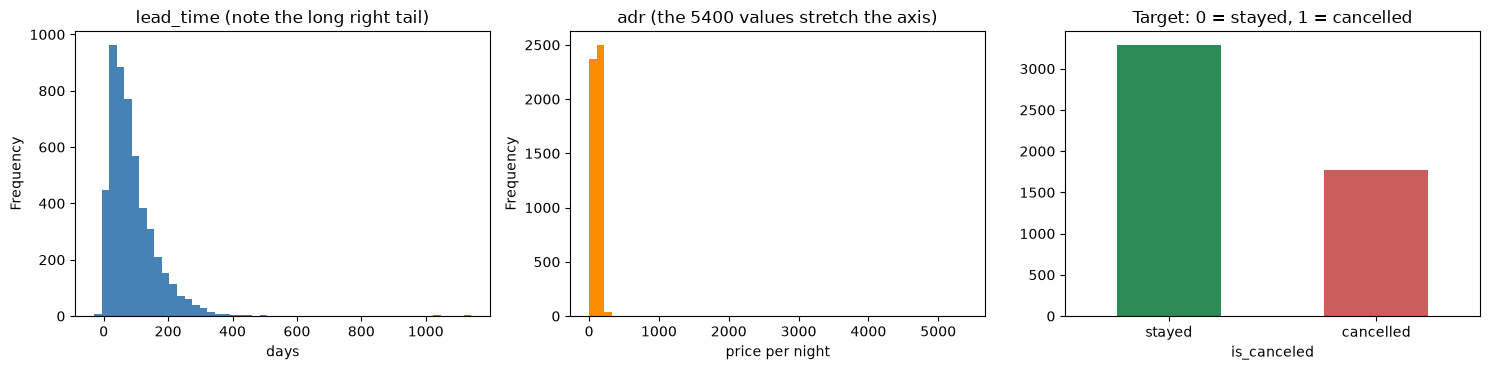

Cancellation rate: 35.0 %


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

raw["lead_time"].plot.hist(bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("lead_time (note the long right tail)"); axes[0].set_xlabel("days")

raw["adr"].plot.hist(bins=50, ax=axes[1], color="darkorange")
axes[1].set_title("adr (the 5400 values stretch the axis)"); axes[1].set_xlabel("price per night")

raw["is_canceled"].value_counts().sort_index().plot.bar(ax=axes[2], color=["seagreen", "indianred"])
axes[2].set_title("Target: 0 = stayed, 1 = cancelled"); axes[2].set_xticklabels(["stayed", "cancelled"], rotation=0)

plt.tight_layout(); plt.show()
print("Cancellation rate:", round(raw["is_canceled"].mean() * 100, 1), "%")

In [30]:
df = raw.copy() # never modify the raw data. Always work on a copy.

before = len(df) # 5060
print("Fully identical rows      :", df.duplicated().sum())
print("Duplicate booking_id      :", df.duplicated(subset="booking_id").sum())

df = df.drop_duplicates(subset="booking_id", keep="first")
print(f"Rows: {before} -> {len(df)}  (removed {before - len(df)})")

Fully identical rows      : 60
Duplicate booking_id      : 60
Rows: 5060 -> 5000  (removed 60)


In [31]:
print("hotel BEFORE :", df["hotel"].value_counts().to_dict())
df["hotel"] = df["hotel"].str.strip().str.title()
print("hotel AFTER  :", df["hotel"].value_counts().to_dict())

print("\ncountry has UK and GB:", sorted([c for c in df["country"].dropna().unique() if c in ("UK", "GB")]))
df["country"] = df["country"].replace({"UK": "GB"})
print("after replace UK->GB :", sorted([c for c in df["country"].dropna().unique() if c in ("UK", "GB")]))

print("\nmeal_plan BEFORE:", df["meal_plan"].value_counts(dropna=False).to_dict())
df["meal_plan"] = df["meal_plan"].replace({"Undefined": np.nan})     
print("meal_plan AFTER :", df["meal_plan"].value_counts(dropna=False).to_dict())

hotel BEFORE : {'City Hotel': 2871, 'Resort Hotel': 1829, ' City Hotel ': 63, 'CITY HOTEL': 59, 'city hotel': 56, 'resort hotel': 44, 'RESORT HOTEL': 41, ' Resort Hotel ': 37}
hotel AFTER  : {'City Hotel': 3049, 'Resort Hotel': 1951}

country has UK and GB: ['GB', 'UK']
after replace UK->GB : ['GB']

meal_plan BEFORE: {'BB': 2906, 'HB': 996, 'SC': 737, 'FB': 211, 'Undefined': 100, nan: 50}
meal_plan AFTER : {'BB': 2906, 'HB': 996, 'SC': 737, 'FB': 211, nan: 150}


In [32]:
df["check_in_date"] = pd.to_datetime(df["check_in_date"], errors="coerce")   # "not available" -> NaT
print("Invalid dates turned into NaT:", df["check_in_date"].isna().sum())

# Derive useful date features (a simple, rule-based transformation)
df["check_in_month"] = df["check_in_date"].dt.month
df["check_in_dow"]   = df["check_in_date"].dt.dayofweek      # Monday = 0
df[["check_in_date", "check_in_month", "check_in_dow"]].head()

Invalid dates turned into NaT: 50


,check_in_date,check_in_month,check_in_dow
0,2025-02-21,2.0,4.0
1,2025-11-20,11.0,3.0
2,2024-04-27,4.0,5.0
3,2025-06-08,6.0,6.0
4,2024-07-22,7.0,0.0


In [33]:
n0 = len(df)

# Rows where the stay itself is not a real stay -> remove
df = df[df["stay_nights"] > 0]
df["children"] = df["children"].fillna(0)                 # business rule: missing = no children
df = df[(df["adults"] + df["children"]) > 0]
print(f"Removed {n0 - len(df)} rows with 0 nights or no guests")

# Impossible NUMBERS -> mark as missing (NaN). We do not delete the row: other columns are still useful.
df.loc[df["lead_time"] < 0, "lead_time"]     = np.nan
df.loc[df["lead_time"] > 730, "lead_time"]   = np.nan
df.loc[(df["adr"] <= 0) | (df["adr"] > 1000), "adr"] = np.nan

print("Rows now:", len(df))
print("\nlead_time range:", df["lead_time"].min(), "to", df["lead_time"].max())
print("adr range      :", df["adr"].min(), "to", df["adr"].max())

Removed 18 rows with 0 nights or no guests
Rows now: 4982

lead_time range: 0.0 to 500.0
adr range      : 44.02 to 302.62


lead_time    IQR fence = [   -86.0,    242.0]  ->  195 values outside (3.9%)
adr          IQR fence = [    19.9,    201.4]  ->   81 values outside (1.7%)
stay_nights  IQR fence = [    -2.5,      9.5]  ->  203 values outside (4.1%)


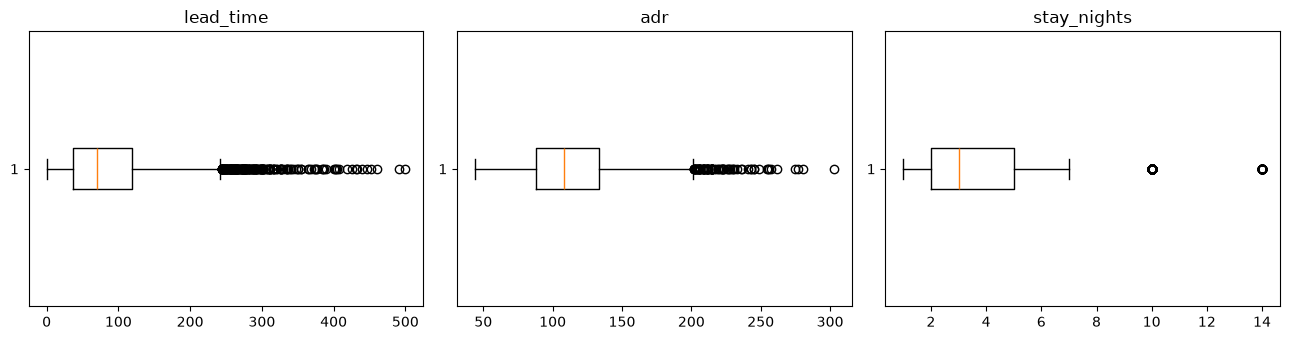

In [34]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in ["lead_time", "adr", "stay_nights"]:
    s = df[col].dropna()
    low, high = iqr_bounds(s)
    n_out = ((s < low) | (s > high)).sum()
    print(f"{col:12s} IQR fence = [{low:8.1f}, {high:8.1f}]  -> {n_out:4d} values outside ({n_out / len(s) * 100:.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["lead_time", "adr", "stay_nights"]):
    ax.boxplot(df[col].dropna(), vert=False); ax.set_title(col)
plt.tight_layout(); plt.show()